# MAB Price Optimization

### Introduction

Objective 
*  Price Optimization without assuming demand shape.

Methodology 
*  MAB (multi-armed bandit) loop with price exploration and regression based demand estimation.
*  Pick among candidate estimation models
*  Innovative tilt adjustment within each candidate models

Test with three demand types
* linear demand
* constant elasticity demand
* logit demand

Candidate demand estimation models
* linear
* log_log
* log_quadratic
* optional log_level 

General Findings
* The overall demand estimation and price optimization functional works for all demand types.
* Accuracy is good for all demand types and especially for Logit and Linear demand. The most challenging demand type is Constant Elasticity (CE). However, Constat Elasticity demand is not so realistic so less accuracy with CE is less concerning.
* Several methods are used to improve accuracy, such as 
  * tilt adjustment on demand esmtation model 
  * price_repeeat which decreases the effective demand noise variance by $\sqrt{n}$



### Organization of this notebook
* Introduction
* Price and Profit Optimization Algorithm Principles
* Demand Parameters
* Revenue and Profit Parameters
* MAB Loop: Optimum Demand, Price, Profit
* Statistical Performance Results

# Price and Profit Optimization Algorithm Principles

### Demand Types

**Constant Elasticity**
* Urealisitc over large price variations, but useful approximation over narrow price regions
* Useful for local approximation, +/- 10 - 20 %, where real demand elasticity can appear constant
* Sometimes groups of products can exhibit constant elasticity, over small price regions
* Esimators struggle to accurately estimate optimum price for large price variations under constant elasticity of demand. Though, estimation over small price regions (+/- 20%) are ok??

**Linear**
* Linear demand is again, like constant elasticity, an approximation, and not a realistic demand function.
* It has two obvious global problems. At sufficiently high prices it predicts negative demand, and at sufficiently low prices it does not naturally represent saturation or a finite population of potential buyers. So, like constant elasticity, we generally shouldn't interpret it as globally valid.
* It is a realistic approximation over a narrow price range. If prices vary only moderately around the economically relevant region, linear demand isn't merely convenient—it is the natural first-order approximation to essentially any smooth demand curve.

**Logit**
* Approximates real world demand behavior
* As price increases price sensitivity increases (elasticity), $\%  \Delta d / \% \Delta p$ and elasticity decreases (price sensitivity) as price falls

## Estimation and Demand Types

**Constant Elasticity demand estimation**
* Test constant elasticity over small price region

**Linear demand estimation**
* Testing of linear demand estimation for for price and profit over a broad region, or small region, produces accurate results.

**Logit demand estimation**
* Test logit and linear elasticity over larger price regions, small and large price variations, produces reasonably accurate results.


### Demand Estimation Model Forms
$$
\log \, d = \beta_0 + \beta_1 \, \log p + \beta_2 (\log p)^2
$$

if $\beta_2 \approx 0$, elasiticiay is approximately constant and log quadratic collapses naturally to log-log (constant elasticity).

However if $\beta_2$ is meaningfully nonzero, there is evidence that elasticity varies with price. 

log quadratic level level (linear) penalty

this model is not the ordinary LogQL model. It changes the entire coefficient-estimation criterion from log-demand RSS to demand-level RSS.

Model Selection
```text
* log-level is optonal ... the typical configuration is three models
* ... linear, log-log, log-quadratic
* these three base models cover, constant elasticity, linear, and logit demand
* log-level OPTIONAL ... linear, log-log, log-quadratic required inputs
                            FIT THREE MODELS
                      linear | log-log | log-quadratic
                              |
                              v
                          Compare RSS
                              |
                      +--------+---------+
                      |                  |
                  LINEAR            LOG MODEL
                      |                  |
                      v                  |
                tilt_imalance?   
                ||TL|,|TH|| >= max       |
                    /     \              |
                  NO      YES            |
                  |        |             |
                  v        v             |
                LINEAR  choose best      |
                        LOG MODEL <------+
                            |
                            v
                    log-quadratic selected?
                        /           \
                      YES            NO
                      |              |
                  beta2 justified?   |
                    /    \           |
                  YES     NO         |
                    |       |        |
                LOG-Q   LOG-LOG      |
                      \      /       |
                      +----+---------+
                            |
                            v
                    Diverged from LINEAR?
                            |
                      YES / \ NO
                          /   \
                      LINEAR   |
                              v
                          Boundary?
                          /      \
                        YES       NO
                          |         |
                        LINEAR    LOG MODEL
                
```           

Selection Logic
So the numbered logic becomes:

1. Fit all three models with their tilt adjustments.
2. Compare models by RSS.
3. If a log model wins RSS, proceed with the existing log-model logic unchanged.

4. If linear wins RSS, check tilt imbalance
$$
  |∣TH∣-∣TL∣| >= _tilt_imbalance_threshold
$$
5. If that is below linear_tilt_max, accept linear immediately.
6. If linear fails the tilt guard, reject it only as the initial winner and choose between log-log and log-quadratic.
7. Apply the existing log-quadratic complexity/AIC check.
8. Apply the existing divergence-from-linear check.
9. Apply the existing boundary check.
10. Either of those final safety checks can still fall back to linear, even if 11. linear previously failed the tilt guard.

## Tilt

Our earlier investigation showed that, with relatively few noisy demand observations, a fitted curve could have a reasonable overall fit but be slightly tilted relative to the underlying demand relationship. That small slope error could translate into a surprisingly large error in the profit-maximizing price.

Rather than imposing a hard constraint on the fitted coefficients, we introduced a soft tilt penalty during estimation 

$$
tilt\_error = \sqrt{r_{low}^2 - r_{high}^2}
$$

Augmented least-squares objective is effectively
$$
\text{weighted RSS} + \lambda(r_{low}^2 + r_{high}^2)
$$

where do we implement lambda ??

Next Steps

1. Clean up select_demand_model. Remove obsolete selection logic while retaining useful diagnostics. We now have a much clearer conceptual architecture: fit → select on fit → AIC complexity check for log-quadratic → divergence guard against linear.

2. Store predictions for every candidate model, not merely the selected model. In particular, I would make the diagnostics for each model self-contained enough that later we can inspect something conceptually like:

3. Re-examine the actual curves before inventing another correction. This is now the most valuable step. For cases like at the high end - linear fall back p_opt_hat ~ 3.10, log models fail at boundry p_opt_hat = 4. ... ,  at the low end (p_opt_hat = 2.51), and some of the very accurate runs, we can plot on the same data:
observed demand
* true demand (simulation only)
* all three fitted demand curves
* all three profit curves / estimated optima
* possibly elasticity curves

That should tell us whether the remaining error comes primarily from tilt, curvature, noisy local data around the optimum, or the profit maximization amplifying a relatively small demand-fit error.

the linear fallback is doing what we intended: acting as a conservative guardrail rather than trying to be the preferred functional form.

There is still a modest upward bias, about 2.834−2.70=0.134, and a few interesting cases remain. 

# Notebook Setup

In [1]:
!python --version

Python 3.12.7


In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path("..") / "py_modules"))

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import beautifulplots as bp


from demand_elasticity_profit import (
    demand_constant_elasticity, 
    demand_linear, elasticity_linear,
    demand_logit, elasticity_logit,
    get_vhat_invumar_df,
)

from utils_probability import demand_sample

# Demand

### Demand Parameters

Business Parameters

These parameters are contexttual to the business problem and are necessary to model demand behavior.
* CV - coefficient of variation. Represents the demand variation relative to the mean, $CV = \sigma/\mu$
* c - cost per unit.
* F - fixed cost.

Below (code cell), we use the term `sigma_log` because the standard deviation corresponds to the log domain corresponding to log D demand variations - additive in the log domain (log scale) and multiplicative in the linear domain  (.e., demand with multiplicative "noisy" variation). This is the typical representation for market demand situations. This $sigma_log$ is often simply termed $\sigma$ in the literature, however both represent stadnard-deviation in the log domain.

In [3]:
# Demand General Parameters
CV =0.2 
v = 1.8
c = 1.2
F = 6
sigma_log = np.sqrt(np.log1p(CV**2)) # sqrt(1 + CV^2)

print(f'CV = {CV}, Coefficient of Variation')
print(f'sigma_log = {sigma_log}')
print(f'v = {1.8}, elasticity')
print(f'c = {c}, variable costs')
print(f'F = {F}, Fixed costs')


CV = 0.2, Coefficient of Variation
sigma_log = 0.19804220043536505
v = 1.8, elasticity
c = 1.2, variable costs
F = 6, Fixed costs


Additonal price parameters
*  p0, is the currently set market price, though it is not optimal.
*  price_min - minimum price guard rail
*  price_max - maximum price guard rail

In [4]:
p0 = 3.6
price_min = 2
price_max = 4.0
print(f'p0 = {p0}, initial price')
print(f'price_min = {price_min}, minimum price')
print(f'price_max = {price_max}, maximum price')

p0 = 3.6, initial price
price_min = 2, minimum price
price_max = 4.0, maximum price


For exemplary purposes, we set the following objectives across the demand functions
1. Profit optimizing price, p_opt, is the same across all the demand functions 
2. Demand, d(p_opt) is the same for all three demand examples.
3. Elasticity at p_opt, is the same for all demand examples.

Demand parameters for the three demand functions - constant elasticity, linear demand, logit demand

We begin with constant elasticity, because it provides conceptual understanding of elasticity. Then, we will set the parameters for the other demand functions to aligned with the profit optimizing price, p_opt, and corresponding elasticity.

In [5]:
# Demand Parameters

#### Constant Elasticity Demand ###
v = 1.8
p_opt = (v / (v - 1)) * c
A_ce = 4000
D_opt = A_ce * p_opt **(-v)
Profit_opt = p_opt * D_opt - c * D_opt - F  

#### linear demand ####
#  - match the slope of the constant elasticity demand at p_opt
#  d_linear = A ( 1 - bp )
#  p_zero = A / b
#  d_linear(p_opt) = d_ce(p_opt)
#  A (1 - b * p_opt) = A * p_opt **(-v)
#  A is known, solve for b
b_linear = v / (( 1 + v) * p_opt)
A_linear = D_opt / (1 - b_linear * p_opt) # A = d(p_opt) / (1 - b * p_opt)

###### Logit #######
# need to solve for a and b
# constraints:
#  1) v_logit(p_opt) =  v = 1.8
#  2) pmid = p_opt
#  b_logit = 2 * v / p_opt ... 
#  a_logit = b_logit * p_opt ... sets the midpoint for logit demand
b_logit =  2 * v / p_opt
a_logit =  b_logit * p_opt
A_logit = 2 * D_opt # Logit demand is A/2 at p_opt

# Constant Elasticity Demand
print('Connstant Elasticity Demand')
print(f'  p_opt = {p_opt}')
print(f'  D_opt = {D_opt}')
print(f'  v = {v}')
print(f'  A_ce = {A_ce}')
print(f'  Profit_opt = {Profit_opt}')

# Linear Demand
print()
print('Linear Demand')
print(f'  A_linear = {A_linear}')
print(f'  b_linear = {b_linear}')

# Logit De`mand
print()
print("Logit Demand")
print(f'  A_logit = {A_logit}')
print(f'  b_logit = {b_logit}')
print(f'  a_logit = {a_logit}')


Connstant Elasticity Demand
  p_opt = 2.6999999999999997
  D_opt = 669.2759448378242
  v = 1.8
  A_ce = 4000
  Profit_opt = 997.9139172567361

Linear Demand
  A_linear = 1873.972645545908
  b_linear = 0.23809523809523814

Logit Demand
  A_logit = 1338.5518896756485
  b_logit = 1.3333333333333335
  a_logit = 3.6


# Revenue Profit Costs

In [6]:
Profit_opt = (p_opt -c) * D_opt -  F

R_opt = p_opt * D_opt

MC = c # marginal cost

TC_p_opt = c * D_opt + F
TCPU_p_opt = TC_p_opt / D_opt

RPU_D_opt = R_opt / D_opt
Profit_opt

print(f'Profit_opt = {Profit_opt}')

Profit_opt = 997.9139172567362


# MAB Loop - Optimum Demand, Price, Profit

mab_experiments results_dict form

```text
results_dict
│
├── observed MAB path
│   ├── p_history
│   ├── d_history
│   └── d_sigma0_history
│
├── selected-model path
│   ├── selected_model              ← selected model at each iteration
│   ├── p_opt_hat_history
│   ├── d_opt_hat_history
│   └── p_opt_hat_error_history
│
├── final selected model
│   ├── selected_model_type
│   ├── dhat_model                  ← selected model prediction function
│   └── model_info                  ← selected model fit information
│
├── model_diagnostics               ← ALL final model diagnostics
│   │
│   ├── linear
│   │   ├── aic
│   │   ├── p_opt_hat
│   │   ├── d_opt_hat
│   │   ├── profit_opt_hat
│   │   ├── tilt_error
│   │   └── ...                     ← other linear diagnostics
│   │
│   ├── log_log
│   │   ├── aic
│   │   ├── p_opt_hat
│   │   ├── d_opt_hat
│   │   ├── profit_opt_hat
│   │   ├── tilt_error
│   │   └── ...                     ← other log-log diagnostics
│   │
│   └── log_quadratic
│       ├── aic
│       ├── p_opt_hat
│       ├── d_opt_hat
│       ├── profit_opt_hat
│       ├── tilt_error
│       ├── beta1
│       ├── beta2
│       └── ...                     ← other log-quadratic diagnostics
│
├── fitted_models                   ← ALL final fitted models
│   │
│   ├── linear
│   │   ├── dhat_model
│   │   └── model_info
│   │
│   ├── log_log
│   │   ├── dhat_model
│   │   └── model_info
│   │
│   └── log_quadratic
│       ├── dhat_model
│       └── model_info
│
├── model_diagnostics_history       ← model_diagnostics at EACH iteration
│   ├── iteration 0
│   ├── iteration 1
│   ├── ...
│   └── final iteration
│
└── fitted_models_history           ← fitted_models at EACH iteration
    ├── iteration 0
    ├── iteration 1
    ├── ...
    └── final iteration
```

### MAB Loop Setup

In [7]:
from demand_price_estimation import mab_price_optimization_loop, get_demand

pd.set_option('display.max_columns', None) # show all columns
pd.set_option('display.max_rows', None) # show all rows

In [73]:
# Demand model and Fit Models 
demand_type = "constant_elasticity"
#demand_type = "linear"
#demand_type = "logit"

demand_params = {}
if demand_type == "constant_elasticity":
    demand_params = {"A": A_ce, "v": v, }

elif demand_type == "linear":
    demand_params = { "A": A_linear, "b": b_linear  }

elif demand_type == "logit":
    demand_params = {  "A": A_logit,"a": a_logit, "b": b_logit,}
    
# fit model
candidate_model_types = [ "linear", "log_level", "log_log", "log_quadratic"] # model types    
candidate_model_types = [ "linear", "log_quadratic", "piecewise_linear"] # model types   
candidate_model_types = [ "linear","log_log" ,"log_quadratic"] # model types 

#candidate_model_types = [ "linear", "log_quadratic"] # model types 
#primary_model_type = "log_quadratic"
#b2_lambda = 1.0


candidate_model_types = [  "linear", "quadratic" ]
primary_model_type = "quadratic"
b2_lambda_q = 0
b2_lambda_lql = 0
b2_lambda_lql_lp = 0.0

#candidate_model_types = [ "linear", "quadratic", "log_quadratic_level"] # model types 
#primary_model_type = "log_quadratic_level"
#b2_lambda_q = 10.0
#b2_lambda_lql = 10.0
#b2_lambda_lql_lp = 0.0


#candidate_model_types = [ "linear", "log_quadratic_level_lp"] # model types 
#primary_model_type = "log_quadratic_level_lp"
#b2_lambda_q = 0.0
#b2_lambda_lql = 0.0
#b2_lambda_lql_lp = 100.0


candidate_model_types = [ "linear", "log_quadratic_level"] # model types 
primary_model_type = "log_quadratic_level"
b2_lambda_q = 0.0
b2_lambda_lql = 0.0
b2_lambda_lql_lp = 0.0


candidate_model_types = [
    "linear",
    "quadratic",
    "log_quadratic_level",
]


candidate_model_types = [
    "linear",
    "quadratic",
    "log_log",
    "log_quadratic",
    "log_quadratic_level",
]

#candidate_model_types = [
#    "linear",
#    "quadratic",
#    "log_log",
#    "log_quadratic",
#]

primary_model_type = "quadratic"
ridge_cv_linear = False
ridge_cv_q = False
ridge_cv_lql = True
b2_lambda_q = 10.0
b2_lambda_lql = 0.0
b2_lambda_lql_lp = 0.0
thr_rss_max = 2
thr_rss_diff_max = .75

#primary_model_type = None
#primary_model_type = None



In [74]:
# MAB Loop Paramter Setup

sigma_lg = sigma_log
#sigma_lg = 0.05
#sigma_lg = 0
N_experiments = 100
price_range = price_max -price_min
price_delta_initial_percent = 0.2  # price delta limited to x %
price_delta_initial = round(price_delta_initial_percent * price_range, 2)
price_delta = 0.10
price_delta_plus = 0.05
price_local_window = False

N_price_repeat = 4
price_repeat_aggregation = False
N_initial_prices = int(price_range/ price_delta_initial)
N_post_init_prices = 4
N_loop = N_price_repeat * N_initial_prices + N_post_init_prices * N_price_repeat 
boundary_buffer = .2
huber = False
ridge_cv = True

linear_rss_guard_max = 3.0

tilt_penalty_linear = 20.0 # linear tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
tilt_penalty_log_level = 10.0 # log-level tilt penalty 
tilt_penalty_log_log = 10.0 # 5 log-log tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
tilt_penalty_log_quadratic = 0.0 #0.0, 5.0 # log-quadratic tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
tilt_penalty_log_quadratic_level = 0.0
linear_tilt_imbalance_max = 0.08  # tilt imbalance threshold for linear model
logq_aic_improvement_min=2.0
p_opt_linear_delta_frac_max=0.15 # maximum allowed fractional deviation of p_opt from linear model

initial_prices = None
initial_demand = None

#initial_prices = [ 2.0, 2.0, 2.0,  2.5, 2.5, 2.5, 3.0, 3.0, 3.0,  3.5, 3.5, 3.5,   4.0, 4.0, 4.0,  2.86, 2.86, 2.91, 2.91, 2.91, 2.94, 2.94, 2.94, 2.94, 2.94, 2.94, 2.95, 2.95, 2.95, 2.95 ]

#initial_demand = [ 819.2, 1023.3, 814.1,  504.1, 760.4, 636.6, 589.9, 606.2, 564.1,  341.2, 342.2, 392.4,128.9, 273.6, 171.8, 645.6, 518.6,  537.4, 589.2, 459.8, 540.7, 598.1, 470.7, 490.6, 770.8, 448.6,  513.0, 587.2, 718.6, 467.2,]

print(f'N_experiments = {N_experiments}')
print(f'Nloop = {N_loop}')
print(f'Nprice_repeat = {N_price_repeat}')
print(f'price_repeat_aggregation = {price_repeat_aggregation}')
print(f'N_initial_prices = {N_initial_prices}')
print(f'N_post_init_prices = {N_post_init_prices}')
print(f'boundary_buffer = {boundary_buffer}')
print(f"demand_type = {demand_type}")
print(f"demand_params = {demand_params}")
print(f'ridge_cv = {ridge_cv}')
print(f"thr_rss_max = {thr_rss_max}")
print(f"thr_rss_diff_max = {thr_rss_diff_max}")
print(f"b2_lambda_q = {b2_lambda_q}")
print(f"b2_lambda_lql = {b2_lambda_lql}")
print(f"b2_lambda_lql_lp = {b2_lambda_lql_lp}")
print(f"sigma_lg = {sigma_lg}")
print(f"candidate_model_types = {candidate_model_types}")
print(f'primary_model_type = {primary_model_type}')
print(f"tilt_penalty_linear = {tilt_penalty_linear}")
print(f'tilt_penalty_log_level = {tilt_penalty_log_level}')
print(f"tilt_penalty_log_log = {tilt_penalty_log_log}")
print(f"tilt_penalty_log_quadratic = {tilt_penalty_log_quadratic}")
print(f"tilt_penalty_log_quadratic_level = {tilt_penalty_log_quadratic_level}")
print(f"linear_tilt_imbalance_max = {linear_tilt_imbalance_max}")
print(f"logq_aic_improvement_min = {logq_aic_improvement_min}")
print(f"p_opt_linear_delta_frac_max = {p_opt_linear_delta_frac_max}")
print(f'price_delta_initial = {price_delta_initial}')   
print(f'price_delta = {price_delta}')
print(f'price_delta_plus = {price_delta_plus}')
print(f'price_local_window = {price_local_window}')
print(f"initial_prices = {initial_prices}")
print(f"initial_demand = {initial_demand}")


N_experiments = 100
Nloop = 36
Nprice_repeat = 4
price_repeat_aggregation = False
N_initial_prices = 5
N_post_init_prices = 4
boundary_buffer = 0.2
demand_type = constant_elasticity
demand_params = {'A': 4000, 'v': 1.8}
ridge_cv = True
thr_rss_max = 2
thr_rss_diff_max = 0.75
b2_lambda_q = 10.0
b2_lambda_lql = 0.0
b2_lambda_lql_lp = 0.0
sigma_lg = 0.19804220043536505
candidate_model_types = ['linear', 'quadratic', 'log_log', 'log_quadratic', 'log_quadratic_level']
primary_model_type = quadratic
tilt_penalty_linear = 20.0
tilt_penalty_log_level = 10.0
tilt_penalty_log_log = 10.0
tilt_penalty_log_quadratic = 0.0
tilt_penalty_log_quadratic_level = 0.0
linear_tilt_imbalance_max = 0.08
logq_aic_improvement_min = 2.0
p_opt_linear_delta_frac_max = 0.15
price_delta_initial = 0.4
price_delta = 0.1
price_delta_plus = 0.05
price_local_window = False
initial_prices = None
initial_demand = None


In [75]:
# ========== MAB Experiment Loop ========================#

verbose = 0

# ----------- print experiment parameters -----------

print(f"N_experiments = {N_experiments}")
print(f"Nloop = {N_loop}")
print(f"Nprice_repeat = {N_price_repeat}")
print(f'price_repeat_aggregation = {price_repeat_aggregation}')
print(f"N_initial_prices = {N_initial_prices}")
print(f'N_post_init_prices = {N_post_init_prices}')
print(f"candidate_model_types = {candidate_model_types}")
print(f'primary_model_type = {primary_model_type}')
print(f"demand_type = {demand_type}")
print(f"ridge_cv_linear = {ridge_cv_linear}")
print(f"ridge_cv_q = {ridge_cv_q}")
print(f"ridge_cv_lql = {ridge_cv_lql}")
print(f"huber = {huber}")
print(f"thr_rss_max = {thr_rss_max}")
print(f"thr_rss_diff_max = {thr_rss_diff_max}")
print(f"b2_lambda_q = {b2_lambda_q}")
print(f"b2_lambda_lql = {b2_lambda_lql}")
print(f"b2_lambda_lql_lp = {b2_lambda_lql_lp}")
print(f"tilt_penalty_linear = {tilt_penalty_linear}")
print(f"tilt_penalty_log_log = {tilt_penalty_log_log}")
print(f"tilt_penalty_log_quadratic = {tilt_penalty_log_quadratic}")
print(f"tilt_penalty_log_quadratic_level = {tilt_penalty_log_quadratic_level}")
print(f"linear_tilt_imbalance_max = {linear_tilt_imbalance_max}")
print(f"p_opt_linear_delta_frac_max = {p_opt_linear_delta_frac_max}")
print(f'price_delta_initial = {price_delta_initial}')   
print(f'price_delta = {price_delta}')
print(f'price_delta_plus = {price_delta_plus}')
print(f'price_local_window = {price_local_window}')
print(f"initial_prices = {initial_prices}")
print(f"initial_demand = {initial_demand}")


# ---------------- experiment histories ----------------

k_history = []
demand_type_history = []
selected_model_history = []

p_opt_hat_history = []
p_opt_hat_error_history = []
d_opt_hat_history = []
sigma_log_history = []

results_dict_list = []


# ---------------- model diagnostics histories ----------------

# p_opt_hat histories
linear_p_opt_hat_history = []
quadratic_p_opt_hat_history = []
log_log_p_opt_hat_history = []
log_quadratic_p_opt_hat_history = []
log_quadratic_level_p_opt_hat_history = []
log_quadratic_level_lp_p_opt_hat_history = []

# Model Selection Diagnostics
p_opt_linear_delta_frac_history = []

# aic histories
linear_aic_history = []
quadratic_aic_history = []
log_log_aic_history = []
log_quadratic_aic_history = []

# rss (residual sum of squares) histories
# log-demand RSS
linear_rss_history = []
quadratic_rss_history = []
log_log_rss_history = []
log_quadratic_rss_history = []
log_quadratic_level_rss_history = []
log_quadratic_level_lp_rss_history = []

# demand-level RSS
linear_rss_level_history = []
quadratic_rss_level_history = []
log_log_rss_level_history = []
log_quadratic_rss_level_history = []
log_quadratic_level_rss_level_history = []
log_quadratic_level_lp_rss_level_history = []

log_quadratic_level_selected_alpha_history = []

# ---------- Regional RSS histories ----------#

# linear
linear_rss_log_low_history = []
linear_rss_log_high_history = []
linear_rss_level_low_history = []
linear_rss_level_high_history = []

# quadratic
quadratic_rss_log_low_history = []
quadratic_rss_log_high_history = []
quadratic_rss_level_low_history = []
quadratic_rss_level_high_history = []

# log-log
log_log_rss_log_low_history = []
log_log_rss_log_high_history = []
log_log_rss_level_low_history = []
log_log_rss_level_high_history = []

# log-quadratic
log_quadratic_rss_log_low_history = []
log_quadratic_rss_log_high_history = []
log_quadratic_rss_level_low_history = []
log_quadratic_rss_level_high_history = []

# log-quadratic-level
log_quadratic_level_rss_log_low_history = []
log_quadratic_level_rss_log_high_history = []
log_quadratic_level_rss_level_low_history = []
log_quadratic_level_rss_level_high_history = []

# log-quadratic-level LP
log_quadratic_level_lp_rss_log_low_history = []
log_quadratic_level_lp_rss_log_high_history = []
log_quadratic_level_lp_rss_level_low_history = []
log_quadratic_level_lp_rss_level_high_history = []


# beta histories, aic, linear delta frac
log_quad_beta1_history = []
log_quad_beta2_history = []
log_quadratic_level_lp_beta2_history = []
logq_vs_loglog_aic_improvement_history = []

# tilt diagnostics histories 

tilt_error_linear_history = []
tilt_error_linear_low_history = []
tilt_error_linear_high_history = []
tilt_imbalance_linear_history = []

tilt_error_log_log_history = []
tilt_error_log_log_low_history = []
tilt_error_log_log_high_history = []

tilt_error_log_quadratic_history = []
tilt_error_log_quadratic_low_history = []
tilt_error_log_quadratic_high_history = []

quadratic_beta1_history = []
quadratic_beta2_history = []

quadratic_vhat_at_linear_p_opt_history = []
quadratic_vhat_delta_from_linear_history = []

ql_1prime_history = []
ql_2prime_history = []
ql_dvhat_dp_history = []
ql_d2d_over_d_history = []
ql_d2d_over_dd_history = []

# log-quadratic-level diagnostics histories 


log_log_vhat_delta_from_linear_history = []
log_quadratic_level_beta2_history = []
log_quadratic_vhat_delta_from_linear_history = []
log_quadratic_level_vhat_delta_from_linear_history = []

log_quadratic_level_lp_vhat_at_linear_p_opt_history = []
log_quadratic_level_lp_vhat_delta_from_linear_history = []

# LogQL-LP curvature diagnostics
logql_lp_1prime_history = []
logql_lp_2prime_history = []
logql_lp_dvhat_dp_history = []
logql_lp_d2d_over_d_history = []
logql_lp_d2d_over_dd_history = []


# ---------------- nonlinear model diagnostics histories ----------------

linear_vhat_at_linear_p_opt_history = []
log_log_vhat_at_linear_p_opt_history = []
log_quadratic_vhat_at_linear_p_opt_history = []
log_quadratic_level_vhat_at_linear_p_opt_history = []

log_log_vhat_delta_from_linear_history = []
log_quadratic_vhat_delta_from_linear_history = []
log_quadratic_level_vhat_delta_from_linear_history = []

# LogQ curvature diagnostics
logq_1prime_history = []
logq_2prime_history = []
logq_dvhat_dp_history = []
logq_d2d_over_d_history = []
logq_d2d_over_dd_history = []

# LogQL curvature diagnostics
logql_1prime_history = []
logql_2prime_history = []
logql_dvhat_dp_history = []
logql_d2d_over_d_history = []
logql_d2d_over_dd_history = []


# ============= Experiments Loop ===================#

for k in range(N_experiments):

    print("k = ", k, end=", ")

    results_dict = mab_price_optimization_loop(
        price_min,
        price_max,
        c,
        F,
        p_opt,
        demand_type,
        demand_params,
        sigma_lg,
        N_loop=N_loop,
        N_price_repeat=N_price_repeat,
        price_repeat_aggregation=price_repeat_aggregation,
        candidate_model_types=candidate_model_types,
        primary_model_type=primary_model_type,
        ridge_cv_linear=ridge_cv_linear,
        ridge_cv_q=ridge_cv_q,
        ridge_cv_lql=ridge_cv_lql,
        huber=huber,
        thr_rss_max=thr_rss_max,
        thr_rss_diff_max=thr_rss_diff_max,
        b2_lambda_q=b2_lambda_q,
        b2_lambda_lql=b2_lambda_lql,
        b2_lambda_lql_lp=b2_lambda_lql_lp,
        price_delta=price_delta,
        price_delta_plus=price_delta_plus,
        price_local_window=price_local_window,
        initial_prices=initial_prices,
        initial_demand=initial_demand,
        boundary_buffer=boundary_buffer,
        N_initial_prices=N_initial_prices,
        tilt_penalty_linear=tilt_penalty_linear,
        tilt_penalty_log_level=tilt_penalty_log_level,
        tilt_penalty_log_log=tilt_penalty_log_log,
        tilt_penalty_log_quadratic=tilt_penalty_log_quadratic,
        tilt_penalty_log_quadratic_level=tilt_penalty_log_quadratic_level,
        linear_tilt_imbalance_max=linear_tilt_imbalance_max,
        logq_aic_improvement_min=logq_aic_improvement_min,
        p_opt_linear_delta_frac_max=p_opt_linear_delta_frac_max,
        verbose=verbose,
    )

    results_dict_list.append(results_dict)


    # ---------- Final results from experiment ----------#

    selected_model_k = results_dict["selected_model_type"]
    p_opt_hat_k = results_dict["p_opt_hat_history"][-1]
    d_opt_hat_k = results_dict["d_opt_hat_history"][-1]

    # Final diagnostics and fitted models for all candidates
    model_diagnostics_k = results_dict["model_diagnostics"]
    fitted_models_k = results_dict["fitted_models"]


    # ---------- Store experiment results ----------#

    k_history.append(k)
    demand_type_history.append(demand_type)
    selected_model_history.append(selected_model_k)

    p_opt_hat_history.append(p_opt_hat_k)

    p_opt_hat_error_history.append(
        abs(p_opt_hat_k - p_opt)
    )

    d_opt_hat_history.append(d_opt_hat_k)
    sigma_log_history.append(sigma_lg)


    # ---------- Model-selection diagnostics ----------#

    p_opt_linear_delta_frac_history.append(model_diagnostics_k[selected_model_k][ "p_opt_linear_delta_frac"])


    # ---------- Linear model diagnostics ----------#

    if "linear" in candidate_model_types:

        linear_aic_history.append( model_diagnostics_k["linear"]["aic"])
        linear_p_opt_hat_history.append( model_diagnostics_k["linear"]["p_opt_hat"])
        linear_rss_history.append(  model_diagnostics_k["linear"]["rss"])
        linear_rss_level_history.append(model_diagnostics_k[ "linear"]["rss_level"])
        linear_rss_log_low_history.append(model_diagnostics_k["linear"]["rss_log_low"])
        linear_rss_log_high_history.append(model_diagnostics_k["linear"]["rss_log_high"]
)
        linear_rss_level_low_history.append(model_diagnostics_k["linear"]["rss_level_low"])
        linear_rss_level_high_history.append(model_diagnostics_k["linear"]["rss_level_high"])
        tilt_error_linear_history.append(model_diagnostics_k["linear"]["tilt_error"])
        tilt_error_linear_low_history.append( model_diagnostics_k["linear"]["tilt_error_low"])
        tilt_error_linear_high_history.append( model_diagnostics_k["linear"]["tilt_error_high"])
        tilt_imbalance_linear_history.append( model_diagnostics_k["linear"]["tilt_imbalance"])
        
        linear_vhat_at_linear_p_opt_history.append(model_diagnostics_k["linear"]["vhat_at_linear_p_opt"])
        
    # ---------- Quadratic model diagnostics ----------#
    if "quadratic" in candidate_model_types:

        quadratic_aic_history.append( model_diagnostics_k["quadratic"]["aic"])
        quadratic_p_opt_hat_history.append( model_diagnostics_k["quadratic"]["p_opt_hat"])
        quadratic_rss_history.append(model_diagnostics_k["quadratic"]["rss"])
        quadratic_rss_level_history.append(model_diagnostics_k["quadratic"]["rss_level"])
        
        quadratic_rss_log_low_history.append(model_diagnostics_k["quadratic"]["rss_log_low"])
        quadratic_rss_log_high_history.append(model_diagnostics_k["quadratic"]["rss_log_high"])
        quadratic_rss_level_low_history.append(model_diagnostics_k["quadratic"]["rss_level_low"])
        quadratic_rss_level_high_history.append(model_diagnostics_k["quadratic"]["rss_level_high"])
        
        quadratic_beta1_history.append(model_diagnostics_k["quadratic"]["beta1"])
        quadratic_beta2_history.append(model_diagnostics_k["quadratic"]["beta2"])
        
        quadratic_vhat_at_linear_p_opt_history.append( model_diagnostics_k["quadratic"]["vhat_at_linear_p_opt"])
        quadratic_vhat_delta_from_linear_history.append(model_diagnostics_k["quadratic"]["vhat_delta_from_linear"])

        # local curvature diagnostics at quadratic p_opt_hat
        ql_1prime_history.append(model_diagnostics_k["quadratic"]["ql_1prime"])
        ql_2prime_history.append(model_diagnostics_k["quadratic"]["ql_2prime"])
        ql_dvhat_dp_history.append(model_diagnostics_k["quadratic"]["ql_dvhat_dp"])
        ql_d2d_over_d_history.append(model_diagnostics_k["quadratic"]["ql_d2d_over_d"])
        ql_d2d_over_dd_history.append( model_diagnostics_k["quadratic"]["ql_d2d_over_dd"])

    # ---------- Log-log model diagnostics ----------#

    if "log_log" in candidate_model_types:

        log_log_aic_history.append(model_diagnostics_k["log_log"]["aic"])
        log_log_p_opt_hat_history.append( model_diagnostics_k["log_log"]["p_opt_hat"])
        log_log_rss_history.append( model_diagnostics_k["log_log"]["rss"])
        log_log_rss_level_history.append(model_diagnostics_k["log_log"]["rss_level"])
        tilt_error_log_log_history.append( model_diagnostics_k["log_log"]["tilt_error"])
        tilt_error_log_log_low_history.append(model_diagnostics_k["log_log"]["tilt_error_low"])
        tilt_error_log_log_high_history.append(  model_diagnostics_k["log_log"]["tilt_error_high"])
        
        log_log_vhat_at_linear_p_opt_history.append(model_diagnostics_k["log_log"]["vhat_at_linear_p_opt"])
        log_log_vhat_delta_from_linear_history.append(model_diagnostics_k["log_log"]["vhat_delta_from_linear"])


    # ---------- Log-quadratic model diagnostics ----------#

    if "log_quadratic" in candidate_model_types:
        log_quadratic_aic_history.append(   model_diagnostics_k["log_quadratic"]["aic"]  )
        log_quadratic_p_opt_hat_history.append( model_diagnostics_k["log_quadratic"]["p_opt_hat"]  )
        log_quadratic_rss_history.append( model_diagnostics_k["log_quadratic"]["rss"]  )
        log_quadratic_rss_level_history.append(model_diagnostics_k["log_quadratic"]["rss_level"])
        
        log_quad_beta1_history.append(  model_diagnostics_k["log_quadratic"]["beta1"])
        log_quad_beta2_history.append(  model_diagnostics_k["log_quadratic"]["beta2"])
        
        tilt_error_log_quadratic_history.append(  model_diagnostics_k["log_quadratic"]["tilt_error"])
        tilt_error_log_quadratic_low_history.append(model_diagnostics_k["log_quadratic"]["tilt_error_low"])
        tilt_error_log_quadratic_high_history.append( model_diagnostics_k["log_quadratic"]["tilt_error_high"])
        log_quadratic_vhat_at_linear_p_opt_history.append(model_diagnostics_k["log_quadratic"]["vhat_at_linear_p_opt"])
        log_quadratic_vhat_delta_from_linear_history.append(model_diagnostics_k["log_quadratic"]["vhat_delta_from_linear"])
        
        # local curvature diagnostics at LogQ p_opt_hat
        logq_1prime_history.append(model_diagnostics_k["log_quadratic"]["logq_1prime"])
        logq_2prime_history.append(model_diagnostics_k["log_quadratic"]["logq_2prime"])
        logq_dvhat_dp_history.append(model_diagnostics_k["log_quadratic"]["logq_dvhat_dp"])
        logq_d2d_over_d_history.append(model_diagnostics_k["log_quadratic"]["logq_d2d_over_d"])
        logq_d2d_over_dd_history.append(model_diagnostics_k["log_quadratic"]["logq_d2d_over_dd"])

    # ---------- Log-quadratic-level model diagnostics ----------#

    if "log_quadratic_level" in candidate_model_types:
        log_quadratic_level_p_opt_hat_history.append(model_diagnostics_k["log_quadratic_level"]["p_opt_hat"])
        log_quadratic_level_rss_history.append( model_diagnostics_k["log_quadratic_level"]["rss"])
        log_quadratic_level_rss_level_history.append(model_diagnostics_k["log_quadratic_level"]["rss_level"])
        
        log_quadratic_level_rss_log_low_history.append(model_diagnostics_k["log_quadratic_level"]["rss_log_low"])
        log_quadratic_level_rss_log_high_history.append(model_diagnostics_k["log_quadratic_level"]["rss_log_high"])
        log_quadratic_level_rss_level_low_history.append(model_diagnostics_k[ "log_quadratic_level"]["rss_level_low"])
        log_quadratic_level_rss_level_high_history.append(model_diagnostics_k[ "log_quadratic_level"]["rss_level_high"])    
        
        
        log_quadratic_level_selected_alpha_history.append(model_diagnostics_k["log_quadratic_level"]["selected_alpha"])
        log_quadratic_level_vhat_at_linear_p_opt_history.append(model_diagnostics_k["log_quadratic_level"]["vhat_at_linear_p_opt"] )
        log_quadratic_level_vhat_delta_from_linear_history.append(model_diagnostics_k["log_quadratic_level"]["vhat_delta_from_linear"])
        log_quadratic_level_beta2_history.append(model_diagnostics_k["log_quadratic_level"]["beta2"])
        # local curvature diagnostics at LogQL p_opt_hat
        logql_1prime_history.append(model_diagnostics_k["log_quadratic_level"]["logql_1prime"])
        logql_2prime_history.append(model_diagnostics_k["log_quadratic_level"]["logql_2prime"])
        logql_dvhat_dp_history.append(model_diagnostics_k["log_quadratic_level"]["logql_dvhat_dp"])
        logql_d2d_over_d_history.append(model_diagnostics_k["log_quadratic_level"]["logql_d2d_over_d"])
        logql_d2d_over_dd_history.append(model_diagnostics_k["log_quadratic_level"]["logql_d2d_over_dd"])
        
        
    # ---------- Log-quadratic-level LP model diagnostics ----------#

    if "log_quadratic_level_lp" in candidate_model_types:

        log_quadratic_level_lp_p_opt_hat_history.append(model_diagnostics_k["log_quadratic_level_lp"]["p_opt_hat"])
        log_quadratic_level_lp_rss_history.append( model_diagnostics_k["log_quadratic_level_lp"]["rss"])
        log_quadratic_level_lp_rss_level_history.append(model_diagnostics_k["log_quadratic_level_lp"]["rss_level"])
        log_quadratic_level_lp_beta2_history.append(model_diagnostics_k["log_quadratic_level_lp"]["beta2"])
        log_quadratic_level_lp_vhat_at_linear_p_opt_history.append(model_diagnostics_k["log_quadratic_level_lp" ]["vhat_at_linear_p_opt"])
        log_quadratic_level_lp_vhat_delta_from_linear_history.append(model_diagnostics_k["log_quadratic_level_lp"]["vhat_delta_from_linear"])

        # local curvature diagnostics at LogQL-LP p_opt_hat
        logql_lp_1prime_history.append( model_diagnostics_k["log_quadratic_level_lp"]["logql_1prime"])
        logql_lp_2prime_history.append(model_diagnostics_k[ "log_quadratic_level_lp"]["logql_2prime"])
        logql_lp_dvhat_dp_history.append( model_diagnostics_k[ "log_quadratic_level_lp"]["logql_dvhat_dp"] )
        logql_lp_d2d_over_d_history.append(model_diagnostics_k["log_quadratic_level_lp" ]["logql_d2d_over_d"])
        logql_lp_d2d_over_dd_history.append( model_diagnostics_k[ "log_quadratic_level_lp" ]["logql_d2d_over_dd"] )
        

    # ---------- Log-log vs. log-quadratic diagnostics ----------#

    if ( "log_log" in candidate_model_types and "log_quadratic" in candidate_model_types):
        logq_vs_loglog_aic_improvement_history.append( model_diagnostics_k["log_quadratic"][ "logq_vs_loglog_aic_improvement" ] )


# ============== Experiment dataframe ============================#

dict_experiments = {

    # experiment results
    "k": k_history,
    "p_opt_hat": p_opt_hat_history,
     "p_opt_error": p_opt_hat_error_history,
    "d_opt_hat": d_opt_hat_history,
    "demand_type": demand_type_history,
    "sigma_log": sigma_log_history,
    "b2_lambda_q": [b2_lambda_q] * len(k_history),
    "b2_lambda_lql": [b2_lambda_lql] * len(k_history),
    "b2_lambda_lql_lp": [b2_lambda_lql_lp] * len(k_history),
    "selected_model": selected_model_history,
    "ridge_cv_linear":[ridge_cv_linear] * len(k_history),
    "ridge_cv_q":[ridge_cv_q] * len(k_history),
    "ridge_cv_lql":[ridge_cv_lql] * len(k_history),
    
}


# ---------- Columns to display ----------#

cols = [
    "k",
    "p_opt_hat",
    "p_opt_error",
    "selected_model",
    "ridge_cv_linear",
    "ridge_cv_q",
    "ridge_cv_lql",
    "b2_lambda_q",
    "b2_lambda_lql",
    "b2_lambda_lql_lp",
    
]


# ---------- Linear model diagnostics ----------#

if "linear" in candidate_model_types:
    dict_linear = {
        "linear_p_opt_hat": linear_p_opt_hat_history,
        "linear_aic": linear_aic_history,
        "linear_rss": linear_rss_history,
        "linear_rss_level": linear_rss_level_history,
    
        "linear_rss_log_low":linear_rss_log_low_history,
        "linear_rss_log_high":linear_rss_log_high_history,
        "linear_rss_level_low":linear_rss_level_low_history,
        "linear_rss_level_high":linear_rss_level_high_history,    
        
        "p_opt_linear_delta_frac": p_opt_linear_delta_frac_history,
        "tilt_error_linear": tilt_error_linear_history,
        "tilt_error_linear_low": tilt_error_linear_low_history,
        "tilt_error_linear_high": tilt_error_linear_high_history,
        "tilt_imbalance_linear": tilt_imbalance_linear_history,
        "linear_vhat_at_linear_p_opt":linear_vhat_at_linear_p_opt_history,
    }

    dict_experiments.update(dict_linear)

    cols_linear = [
        "linear_p_opt_hat",
        "linear_rss",
        "linear_rss_level",
        
        "linear_rss_log_low",
        "linear_rss_log_high",
        "linear_rss_level_low",
        "linear_rss_level_high",
        
        "p_opt_linear_delta_frac",
        "tilt_error_linear",
        "tilt_error_linear_low",
        "tilt_error_linear_high",
        "tilt_imbalance_linear",
        "linear_vhat_at_linear_p_opt",
    ]

    cols.extend(cols_linear)
    
# ---------- Quadratic model diagnostics ----------#

if "quadratic" in candidate_model_types:

    dict_quadratic = {
        "quadratic_p_opt_hat": quadratic_p_opt_hat_history,
        "quadratic_aic": quadratic_aic_history,
        "quadratic_rss": quadratic_rss_history,
        "quadratic_rss_level": quadratic_rss_level_history,
        
        "quadratic_rss_log_low":quadratic_rss_log_low_history,
        "quadratic_rss_log_high":quadratic_rss_log_high_history,
        "quadratic_rss_level_low":quadratic_rss_level_low_history,
        "quadratic_rss_level_high":quadratic_rss_level_high_history,
        
        "quadratic_beta1": quadratic_beta1_history,
        "quadratic_beta2": quadratic_beta2_history,

        "quadratic_vhat_at_linear_p_opt": quadratic_vhat_at_linear_p_opt_history,
        "quadratic_vhat_delta_from_linear":quadratic_vhat_delta_from_linear_history,

        # quadratic local curvature diagnostics
        "ql_1prime": ql_1prime_history,
        "ql_2prime": ql_2prime_history,
        "ql_dvhat_dp": ql_dvhat_dp_history,
        "ql_d2d_over_d": ql_d2d_over_d_history,
        "ql_d2d_over_dd": ql_d2d_over_dd_history,
    }

    dict_experiments.update(
        dict_quadratic
    )

    cols_quadratic = [
        "quadratic_p_opt_hat",
        "quadratic_aic",
        "quadratic_rss",
        "quadratic_rss_level",
        "quadratic_rss_log_low",
        "quadratic_rss_log_high",
        "quadratic_rss_level_low",
        "quadratic_rss_level_high",
        "quadratic_beta1",
        "quadratic_beta2",
        "quadratic_vhat_at_linear_p_opt",
        "quadratic_vhat_delta_from_linear",
        "ql_1prime",
        "ql_2prime",
        "ql_dvhat_dp",
        "ql_d2d_over_d",
        "ql_d2d_over_dd",
    ]

    cols.extend(
        cols_quadratic
    )


# ---------- Log-log model diagnostics ----------#

if "log_log" in candidate_model_types:

    dict_log_log = {
        "log_log_p_opt_hat": log_log_p_opt_hat_history,
        "log_log_aic": log_log_aic_history,
        "log_log_rss": log_log_rss_history,
        "log_log_rss_level":log_log_rss_level_history,
        "tilt_error_log_log": tilt_error_log_log_history,
        "tilt_error_log_log_low": tilt_error_log_log_low_history,
        "tilt_error_log_log_high": tilt_error_log_log_high_history,
        "log_log_vhat_at_linear_p_opt":log_log_vhat_at_linear_p_opt_history,
        "log_log_vhat_delta_from_linear":log_log_vhat_delta_from_linear_history,}

    dict_experiments.update(dict_log_log)

    cols_log_log = [
        "log_log_p_opt_hat",
        "log_log_rss",
        "log_log_rss_level",
        "tilt_error_log_log",
        "tilt_error_log_log_low",
        "tilt_error_log_log_high",
        "log_log_vhat_at_linear_p_opt",
        "log_log_vhat_delta_from_linear",
    ]

    cols.extend(cols_log_log)


# ---------- Log-quadratic model diagnostics ----------#

if "log_quadratic" in candidate_model_types:

    dict_log_quadratic = {
        "log_quadratic_p_opt_hat": log_quadratic_p_opt_hat_history,
        "log_quadratic_aic": log_quadratic_aic_history,
        "log_quadratic_rss": log_quadratic_rss_history,
        "log_quadratic_rss_level":log_quadratic_rss_level_history,
        "log_quad_beta1": log_quad_beta1_history,
        "log_quad_beta2": log_quad_beta2_history,
        "tilt_error_log_quadratic": tilt_error_log_quadratic_history,
        "tilt_error_log_quadratic_low": tilt_error_log_quadratic_low_history,
        "tilt_error_log_quadratic_high": tilt_error_log_quadratic_high_history,
        "log_quadratic_vhat_at_linear_p_opt": log_quadratic_vhat_at_linear_p_opt_history,
        "log_quadratic_vhat_delta_from_linear": log_quadratic_vhat_delta_from_linear_history,
        "logq_1prime": logq_1prime_history,
        "logq_2prime": logq_2prime_history,
        "logq_dvhat_dp": logq_dvhat_dp_history,
        "logq_d2d_over_d": logq_d2d_over_d_history,
        "logq_d2d_over_dd": logq_d2d_over_dd_history,
        }

    dict_experiments.update(dict_log_quadratic)

    cols_log_quadratic = [
        "log_quadratic_p_opt_hat",
        "log_quadratic_rss",
        
        "log_quad_beta1",
        "log_quad_beta2",
        "tilt_error_log_quadratic",
        "tilt_error_log_quadratic_low",
        "tilt_error_log_quadratic_high",
        "log_quadratic_vhat_at_linear_p_opt",
        "log_quadratic_vhat_delta_from_linear",
        "logq_1prime",
        "logq_2prime",
        "logq_dvhat_dp",
        "logq_d2d_over_d",
        "logq_d2d_over_dd",
    ]

    cols.extend(cols_log_quadratic)
    
    
# ---------- Log-quadratic-level LP model diagnostics ----------#

if "log_quadratic_level_lp" in candidate_model_types:

    dict_log_quadratic_level_lp = {
        "log_quadratic_level_lp_p_opt_hat": log_quadratic_level_lp_p_opt_hat_history,
        
        "log_quadratic_level_lp_rss": log_quadratic_level_lp_rss_history,
        "log_quadratic_level_lp_rss_level":log_quadratic_level_lp_rss_level_history,
        "log_quadratic_level_selected_alpha":log_quadratic_level_selected_alpha_history,
        "log_quadratic_level_lp_beta2": log_quadratic_level_lp_beta2_history,
        "log_quadratic_level_lp_vhat_at_linear_p_opt": log_quadratic_level_lp_vhat_at_linear_p_opt_history,
        "log_quadratic_level_lp_vhat_delta_from_linear": log_quadratic_level_lp_vhat_delta_from_linear_history,
        "logql_lp_1prime": logql_lp_1prime_history,
        "logql_lp_2prime": logql_lp_2prime_history,
        "logql_lp_dvhat_dp": logql_lp_dvhat_dp_history,
        "logql_lp_d2d_over_d": logql_lp_d2d_over_d_history,
        "logql_lp_d2d_over_dd": logql_lp_d2d_over_dd_history,
    }

    dict_experiments.update(
        dict_log_quadratic_level_lp
    )

    cols_log_quadratic_level_lp = [

        "log_quadratic_level_lp_p_opt_hat",
        "log_quadratic_level_lp_rss",
        "log_quadratic_level_lp_rss_level",
        "log_quadratic_level_lp_beta2",
        "log_quadratic_level_lp_vhat_at_linear_p_opt",
        "log_quadratic_level_lp_vhat_delta_from_linear",
        "logql_lp_1prime",
        "logql_lp_2prime",
        "logql_lp_dvhat_dp",
        "logql_lp_d2d_over_d",
        "logql_lp_d2d_over_dd",
    ]

    cols.extend(
        cols_log_quadratic_level_lp
    )
    
# ---------- Log-quadratic-level model diagnostics ----------#

if "log_quadratic_level" in candidate_model_types:

    dict_log_quadratic_level = {
        "log_quadratic_level_p_opt_hat": log_quadratic_level_p_opt_hat_history,
        "log_quadratic_level_rss":log_quadratic_level_rss_history,
        
        "log_quadratic_level_rss_level": log_quadratic_level_rss_level_history,
        "log_quadratic_level_rss_log_low": log_quadratic_level_rss_log_low_history,
        "log_quadratic_level_rss_log_high": log_quadratic_level_rss_log_high_history,
        "log_quadratic_level_rss_level_low": log_quadratic_level_rss_level_low_history,
        "log_quadratic_level_rss_level_high": log_quadratic_level_rss_level_high_history,
        
        "log_quadratic_level_beta2":log_quadratic_level_beta2_history,
        "log_quadratic_level_vhat_at_linear_p_opt":log_quadratic_level_vhat_at_linear_p_opt_history,
        "log_quadratic_level_vhat_delta_from_linear":log_quadratic_level_vhat_delta_from_linear_history,
        "logql_1prime": logql_1prime_history,
        "logql_2prime": logql_2prime_history,
        "logql_dvhat_dp": logql_dvhat_dp_history,
        "logql_d2d_over_d": logql_d2d_over_d_history,
        "logql_d2d_over_dd": logql_d2d_over_dd_history,
    }

    dict_experiments.update(dict_log_quadratic_level)

    cols_log_quadratic_level = [
        "log_quadratic_level_p_opt_hat",
        "log_quadratic_level_rss",
        "log_quadratic_level_rss_level",
        "log_quadratic_level_rss_log_low",
        "log_quadratic_level_rss_log_high",
        "log_quadratic_level_rss_level_low",
        "log_quadratic_level_rss_level_high",
        "log_quadratic_level_beta2",
        "log_quadratic_level_vhat_at_linear_p_opt",
        "log_quadratic_level_vhat_delta_from_linear",
        "logql_1prime",
        "logql_2prime",
        "logql_dvhat_dp",
        "logql_d2d_over_d",
        "logql_d2d_over_dd",
    ]

    cols.extend(cols_log_quadratic_level)


# ---------- Log-log vs. log-quadratic diagnostics ----------#

if ( "log_log" in candidate_model_types and "log_quadratic" in candidate_model_types):

    dict_log_models = {
        "logq_vs_loglog_aic_improvement":
            logq_vs_loglog_aic_improvement_history,
    }

    dict_experiments.update(dict_log_models)
    cols.extend([ "logq_vs_loglog_aic_improvement",])


# ---------- Create dataframe ----------#

df_experiments = pd.DataFrame(dict_experiments)


# ============ Display experiment results =============================#

display( df_experiments[cols]  .sort_values(   "p_opt_hat", ascending=False,   ) .head(20))
print("...")
display(  df_experiments[cols] .sort_values(    "p_opt_hat",   ascending=False,   ) .tail(20))
#display( df_experiments[cols]  .sort_values(   "p_opt_hat", ascending=False,   ) .head(100))

# ======== Experiment parameters ===========================#

print(f"N_experiments = {N_experiments}")
print(f"Nloop = {N_loop}")
print(f"Nprice_repeat = {N_price_repeat}")
print(f'price_repeat_aggregation = {price_repeat_aggregation}')
print(f"N_initial_prices = {N_initial_prices}")
print(f'N_post_init_prices = {N_post_init_prices}')
print(f"candidate_model_types = {candidate_model_types}")
print(f'primary_model_type = {primary_model_type}')
print(f"demand_type = {demand_type}")
print(f"ridge_cv_linear = {ridge_cv_linear}")
print(f"ridge_cv_q = {ridge_cv_q}")
print(f"ridge_cv_lql = {ridge_cv_lql}")
print(f"huber = {huber}")
print(f"thr_rss_max = {thr_rss_max}")
print(f"thr_rss_diff_max = {thr_rss_diff_max}")
print(f"b2_lambda_q = {b2_lambda_q}")
print(f"b2_lambda_lql = {b2_lambda_lql}")
print(f"b2_lambda_lql_lp = {b2_lambda_lql_lp}")
print(f"tilt_penalty_linear = {tilt_penalty_linear}")
print(f"tilt_penalty_log_log = {tilt_penalty_log_log}")
print(f"tilt_penalty_log_quadratic = {tilt_penalty_log_quadratic}")
print(f"tilt_penalty_log_quadratic_level = {tilt_penalty_log_quadratic_level}")
print(f"linear_tilt_imbalance_max = {linear_tilt_imbalance_max}")
print(f"p_opt_linear_delta_frac_max = {p_opt_linear_delta_frac_max}")
print(f'price_delta_initial = {price_delta_initial}')   
print(f'price_delta = {price_delta}')
print(f'price_delta_plus = {price_delta_plus}')
print(f'price_local_window = {price_local_window}')
print(f"initial_prices = {initial_prices}")
print(f"initial_demand = {initial_demand}")

display( df_experiments["p_opt_hat"].describe())

N_experiments = 100
Nloop = 36
Nprice_repeat = 4
price_repeat_aggregation = False
N_initial_prices = 5
N_post_init_prices = 4
candidate_model_types = ['linear', 'quadratic', 'log_log', 'log_quadratic', 'log_quadratic_level']
primary_model_type = quadratic
demand_type = constant_elasticity
ridge_cv_linear = False
ridge_cv_q = False
ridge_cv_lql = True
huber = False
thr_rss_max = 2
thr_rss_diff_max = 0.75
b2_lambda_q = 10.0
b2_lambda_lql = 0.0
b2_lambda_lql_lp = 0.0
tilt_penalty_linear = 20.0
tilt_penalty_log_log = 10.0
tilt_penalty_log_quadratic = 0.0
tilt_penalty_log_quadratic_level = 0.0
linear_tilt_imbalance_max = 0.08
p_opt_linear_delta_frac_max = 0.15
price_delta_initial = 0.4
price_delta = 0.1
price_delta_plus = 0.05
price_local_window = False
initial_prices = None
initial_demand = None
k =  0, k =  1, k =  2, k =  3, k =  4, k =  5, k =  6, k =  7, k =  8, k =  9, k =  10, k =  11, k =  12, k =  13, k =  14, k =  15, k =  16, k =  17, k =  18, k =  19, k =  20, k =  21, k =  22, 

,k,p_opt_hat,p_opt_error,selected_model,ridge_cv_linear,ridge_cv_q,ridge_cv_lql,b2_lambda_q,b2_lambda_lql,b2_lambda_lql_lp,linear_p_opt_hat,linear_rss,linear_rss_level,linear_rss_log_low,linear_rss_log_high,linear_rss_level_low,linear_rss_level_high,p_opt_linear_delta_frac,tilt_error_linear,tilt_error_linear_low,tilt_error_linear_high,tilt_imbalance_linear,linear_vhat_at_linear_p_opt,quadratic_p_opt_hat,quadratic_aic,quadratic_rss,quadratic_rss_level,quadratic_rss_log_low,quadratic_rss_log_high,quadratic_rss_level_low,quadratic_rss_level_high,quadratic_beta1,quadratic_beta2,quadratic_vhat_at_linear_p_opt,quadratic_vhat_delta_from_linear,ql_1prime,ql_2prime,ql_dvhat_dp,ql_d2d_over_d,ql_d2d_over_dd,log_log_p_opt_hat,log_log_rss,log_log_rss_level,tilt_error_log_log,tilt_error_log_log_low,tilt_error_log_log_high,log_log_vhat_at_linear_p_opt,log_log_vhat_delta_from_linear,log_quadratic_p_opt_hat,log_quadratic_rss,log_quad_beta1,log_quad_beta2,tilt_error_log_quadratic,tilt_error_log_quadratic_low,tilt_error_log_quadratic_high,log_quadratic_vhat_at_linear_p_opt,log_quadratic_vhat_delta_from_linear,logq_1prime,logq_2prime,logq_dvhat_dp,logq_d2d_over_d,logq_d2d_over_dd,log_quadratic_level_p_opt_hat,log_quadratic_level_rss,log_quadratic_level_rss_level,log_quadratic_level_rss_log_low,log_quadratic_level_rss_log_high,log_quadratic_level_rss_level_low,log_quadratic_level_rss_level_high,log_quadratic_level_beta2,log_quadratic_level_vhat_at_linear_p_opt,log_quadratic_level_vhat_delta_from_linear,logql_1prime,logql_2prime,logql_dvhat_dp,logql_d2d_over_d,logql_d2d_over_dd,logq_vs_loglog_aic_improvement
2,2,3.37,0.67,log_log,False,False,True,10.0,0.0,0.0,3.082164,1.749521,5.076718e+05,0.385936,0.818703,238858.068499,126228.071427,0.142285,0.289913,19.222614,18.932702,0.289913,1.636699,3.170341,-108.168517,1.510093,477885.868097,0.393640,0.616287,248430.495072,100365.662675,-480.310386,31.139980,1.527418,-0.109281,-282.861696,62.279960,0.971972,0.111877,-0.220178,3.366733,1.427082,526658.915760,0.001614,0.002918,0.001304,1.553355,-0.083344,3.627255,1.381791,-0.912849,-0.225808,0.067150,0.041598,-0.025552,1.421204,-0.215495,-0.412088,0.079283,0.124507,0.249100,-0.604482,3.370741,1.393921,473144.590651,0.427485,0.526709,274750.796921,85618.061431,0.014301,1.445271,-0.191428,-0.460661,0.028601,0.364253,0.240809,-0.522748,-0.838959
23,23,3.31,0.61,log_log,False,False,True,10.0,0.0,0.0,3.046092,1.628032,5.881398e+05,0.610391,0.444700,350615.772715,62678.006909,0.134269,0.255266,1.847348,2.102614,0.255266,1.651676,2.957916,-109.918626,1.438437,507607.355523,0.534903,0.327177,282731.724267,48400.658845,-680.307625,55.317346,1.773286,0.121610,-353.059516,110.634693,0.999487,0.178323,-0.313360,3.314629,1.225793,432232.875640,0.000021,-0.030227,-0.030206,1.567360,-0.084316,4.000000,1.219834,-2.168974,0.287955,0.005940,-0.031462,-0.037403,1.527492,-0.124184,-0.342649,0.121656,-0.143977,0.239065,-0.697696,3.230461,1.234122,438065.043093,0.402629,0.242351,210985.873282,37456.764765,0.091981,1.603804,-0.047871,-0.492595,0.183963,-0.101690,0.426613,-0.866052,-1.824559
99,99,3.30,0.60,log_log,False,False,True,10.0,0.0,0.0,3.026052,1.832630,7.814714e+05,0.687470,0.614817,497912.080929,97661.405011,0.136273,0.008170,-3.043605,-3.051776,0.008170,1.656763,3.006012,-105.619086,1.620912,727375.031666,0.651496,0.437883,463997.114446,76040.128193,-611.396264,46.521015,1.682243,0.025480,-331.710805,93.042029,1.005600,0.155080,-0.280491,3.298597,1.485056,675891.404101,0.000708,-0.038953,-0.039661,1.571358,-0.085405,3.434870,1.476126,-1.268360,-0.108659,0.030516,-0.021793,-0.052309,1.508988,-0.147775,-0.447332,0.111813,0.063268,0.311919,-0.697288,3.150301,1.516856,728940.793693,0.615744,0.364445,470215.619747,64770.143861,-0.016998,1.539774,-0.116989,-0.513063,-0.033997,0.620163,0.229237,-0.446801,-1.782884
88,88,3.27,0.57,log_log,False,False,True,10.0,0.0,0.0,2.981964,1.843760,6.659579e+05,0.320780,0.603271,255886.309118,90952.807467,0.142285,0.087643,37.302523,37.39016

...


,k,p_opt_hat,p_opt_error,selected_model,ridge_cv_linear,ridge_cv_q,ridge_cv_lql,b2_lambda_q,b2_lambda_lql,b2_lambda_lql_lp,linear_p_opt_hat,linear_rss,linear_rss_level,linear_rss_log_low,linear_rss_log_high,linear_rss_level_low,linear_rss_level_high,p_opt_linear_delta_frac,tilt_error_linear,tilt_error_linear_low,tilt_error_linear_high,tilt_imbalance_linear,linear_vhat_at_linear_p_opt,quadratic_p_opt_hat,quadratic_aic,quadratic_rss,quadratic_rss_level,quadratic_rss_log_low,quadratic_rss_log_high,quadratic_rss_level_low,quadratic_rss_level_high,quadratic_beta1,quadratic_beta2,quadratic_vhat_at_linear_p_opt,quadratic_vhat_delta_from_linear,ql_1prime,ql_2prime,ql_dvhat_dp,ql_d2d_over_d,ql_d2d_over_dd,log_log_p_opt_hat,log_log_rss,log_log_rss_level,tilt_error_log_log,tilt_error_log_log_low,tilt_error_log_log_high,log_log_vhat_at_linear_p_opt,log_log_vhat_delta_from_linear,log_quadratic_p_opt_hat,log_quadratic_rss,log_quad_beta1,log_quad_beta2,tilt_error_log_quadratic,tilt_error_log_quadratic_low,tilt_error_log_quadratic_high,log_quadratic_vhat_at_linear_p_opt,log_quadratic_vhat_delta_from_linear,logq_1prime,logq_2prime,logq_dvhat_dp,logq_d2d_over_d,logq_d2d_over_dd,log_quadratic_level_p_opt_hat,log_quadratic_level_rss,log_quadratic_level_rss_level,log_quadratic_level_rss_log_low,log_quadratic_level_rss_log_high,log_quadratic_level_rss_level_low,log_quadratic_level_rss_level_high,log_quadratic_level_beta2,log_quadratic_level_vhat_at_linear_p_opt,log_quadratic_level_vhat_delta_from_linear,logql_1prime,logql_2prime,logql_dvhat_dp,logql_d2d_over_d,logql_d2d_over_dd,logq_vs_loglog_aic_improvement
90,90,2.71,1.000000e-02,quadratic,False,False,True,10.0,0.0,0.0,2.757515,4.429546,1.140459e+06,0.791533,3.365069,6.744965e+05,331470.925006,0.024048,0.689955,22.484867,21.794912,0.689955,1.773600,2.709419,-98.736580,1.962402,9.036222e+05,0.722283,1.012041,6.098364e+05,185308.454769,-996.520951,92.338165,1.855925,0.082325,-496.155424,184.676330,1.187620,0.247014,-0.372215,2.501002,1.487368,6.970452e+05,0.000087,-0.000217,-0.000304,1.921184,0.147584,2.176353,1.461697,-3.150329,0.592392,0.005707,-0.008740,-0.003033,1.948566,0.174967,-1.024182,0.720734,-0.544390,1.769682,-1.727899,2.404810,1.486392,6.907369e+05,0.584114,0.697449,455844.237300,145584.018004,0.150355,1.996317,0.222717,-0.830017,0.300710,0.106866,0.989639,-1.192311,-1.373236
25,25,2.71,1.000000e-02,quadratic,False,False,True,10.0,0.0,0.0,2.765531,4.683271,1.579870e+06,0.787771,3.455350,9.381967e+05,429660.737276,0.026052,0.748798,14.463334,13.714536,0.748798,1.763662,2.713427,-92.531412,2.331555,1.295881e+06,0.690662,1.219137,8.454813e+05,252143.921268,-1026.999571,101.229928,1.852548,0.088886,-477.639561,202.459856,1.088519,0.280455,-0.423876,2.537074,1.947537,1.066585e+06,0.000453,-0.010331,-0.010784,1.897275,0.133613,2.108216,1.899965,-3.490936,0.783938,0.005688,-0.014492,-0.020180,1.896043,0.132380,-1.101191,0.875094,-0.743697,2.087716,-1.895871,2.645291,1.976391,1.138171e+06,0.568084,0.981098,747231.983238,198603.456583,0.095404,1.849113,0.085450,-0.691571,0.190809,0.186826,0.669080,-0.967478,-1.109707
10,10,2.71,1.000000e-02,quadratic,False,False,True,10.0,0.0,0.0,2.809619,3.026762,1.379052e+06,0.742013,1.342194,8.136692e+05,147194.675620,0.048096,0.098628,25.872606,25.773978,0.098628,1.742563,2.713427,-94.748241,2.192312,1.199121e+06,0.659721,0.636517,7.035524e+05,90355.436435,-952.044298,84.768888,1.914667,0.172104,-492.015942,169.537777,1.227698,0.227688,-0.344578,2.509018,1.875785,9.989376e+05,0.000283,-0.007941,-0.007657,1.916140,0.173577,2.452906,1.874389,-2.023607,0.036895,0.012974,-0.014822,-0.001849,1.947379,0.204816,-0.797991,0.337589,-0.030083,0.974379,-1.221040,2.709419,1.931369,1.134119e+06,0.590103,0.501202,679864.171679,66265.063109,0.002727,1.860275,0.117712,-0.662656,0.005454,0.647880,0.444566,-0.670885,-1.973210
47,47,2.71,1.000000e-02,quadratic,False,False,True,10.0,0.0,0.0,2.661323,8.407799,1.291256e+06,0.450222,7.459779,5.613561e+05,410028.530228,0.024048,1.

N_experiments = 100
Nloop = 36
Nprice_repeat = 4
price_repeat_aggregation = False
N_initial_prices = 5
N_post_init_prices = 4
candidate_model_types = ['linear', 'quadratic', 'log_log', 'log_quadratic', 'log_quadratic_level']
primary_model_type = quadratic
demand_type = constant_elasticity
ridge_cv_linear = False
ridge_cv_q = False
ridge_cv_lql = True
huber = False
thr_rss_max = 2
thr_rss_diff_max = 0.75
b2_lambda_q = 10.0
b2_lambda_lql = 0.0
b2_lambda_lql_lp = 0.0
tilt_penalty_linear = 20.0
tilt_penalty_log_log = 10.0
tilt_penalty_log_quadratic = 0.0
tilt_penalty_log_quadratic_level = 0.0
linear_tilt_imbalance_max = 0.08
p_opt_linear_delta_frac_max = 0.15
price_delta_initial = 0.4
price_delta = 0.1
price_delta_plus = 0.05
price_local_window = False
initial_prices = None
initial_demand = None


count    100.000000
mean       2.857700
std        0.187179
min        2.540000
25%        2.720000
50%        2.810000
75%        2.982500
max        3.370000
Name: p_opt_hat, dtype: float64

In [78]:
df_experiments["o"] = 1
df_experiments["oo"] = 1
df_experiments["ooo"] = 1
df_experiments["oooo"] = 1

cols =  [
    "k",
    "p_opt_hat",
    "p_opt_error",
    "selected_model",
    "o",
    "linear_rss",
    "linear_rss_log_low",
    "linear_rss_log_high",
    "sum_rss_low_high",
    "diff_rss_high_low",
    "oo",
    "linear_p_opt_hat",
    "quadratic_p_opt_hat",
    "log_log_p_opt_hat",
    "log_quadratic_level_p_opt_hat",	
    "log_quadratic_p_opt_hat",
     "ooo",

    "quadratic_rss",
    "log_quadratic_rss",
    "oooo",
    "quadratic_rss_log_low",
    "quadratic_rss_log_high",
    "log_quadratic_level_rss_log_low",
    "log_quadratic_level_rss_log_high",
    
]

df_experiments["sum_rss_low_high"] = df_experiments["linear_rss_log_low"] + df_experiments["linear_rss_log_high"] 
df_experiments["diff_rss_high_low"] = np.abs(df_experiments["linear_rss_log_low"] - df_experiments["linear_rss_log_high"] )

#display( df_experiments[cols]  .sort_values(   "p_opt_hat", ascending=False,   ) .head(20))
#print("...")
#display(  df_experiments[cols] .sort_values( "p_opt_hat", ascending=False,  ) .tail(20))
display( df_experiments[cols].sort_values("p_opt_hat", ascending=False) .head(100))


,k,p_opt_hat,p_opt_error,selected_model,o,linear_rss,linear_rss_log_low,linear_rss_log_high,sum_rss_low_high,diff_rss_high_low,oo,linear_p_opt_hat,quadratic_p_opt_hat,log_log_p_opt_hat,log_quadratic_level_p_opt_hat,log_quadratic_p_opt_hat,ooo,quadratic_rss,log_quadratic_rss,oooo,quadratic_rss_log_low,quadratic_rss_log_high,log_quadratic_level_rss_log_low,log_quadratic_level_rss_log_high
2,2,3.37,6.700000e-01,log_log,1,1.749521,0.385936,0.818703,1.204639,0.432767,1,3.082164,3.170341,3.366733,3.370741,3.627255,1,1.510093,1.381791,1,0.393640,0.616287,0.427485,0.526709
23,23,3.31,6.100000e-01,log_log,1,1.628032,0.610391,0.444700,1.055091,0.165691,1,3.046092,2.957916,3.314629,3.230461,4.000000,1,1.438437,1.219834,1,0.534903,0.327177,0.402629,0.242351
99,99,3.30,6.000000e-01,log_log,1,1.832630,0.687470,0.614817,1.302287,0.072652,1,3.026052,3.006012,3.298597,3.150301,3.434870,1,1.620912,1.476126,1,0.651496,0.437883,0.615744,0.364445
88,88,3.27,5.700000e-01,log_log,1,1.843760,0.320780,0.603271,0.924051,0.282490,1,2.981964,2.917836,3.266533,4.000000,4.000000,1,1.445456,1.122998,1,0.282045,0.344710,0.277720,0.169922
45,45,3.26,5.600000e-01,quadratic,1,1.707390,0.553039,0.563886,1.116925,0.010847,1,3.282565,3.258517,4.000000,4.000000,4.000000,1,1.434088,1.139576,1,0.435237,0.500203,0.333959,0.423454
43,43,3.25,5.500000e-01,log_log,1,1.264929,0.188921,0.517410,0.706331,0.328488,1,3.006012,2.925852,3.246493,4.000000,4.000000,1,0.909450,0.619787,1,0.136677,0.298318,0.108183,0.116740
77,77,3.25,5.500000e-01,log_log,1,1.722947,0.246854,0.819499,1.066353,0.572646,1,3.042084,3.026052,3.254509,4.000000,4.000000,1,1.401820,1.194795,1,0.225235,0.592393,0.234709,0.474518
33,33,3.23,5.300000e-01,log_log,1,1.469130,0.588169,0.550079,1.138247,0.038090,1,3.014028,2.893788,3.226453,3.042084,4.000000,1,1.247028,0.991756,1,0.506101,0.461376,0.410535,0.408953
89,89,3.19,4.900000e-01,log_quadratic,1,1.087995,0.116638,0.539476,0.656114,0.422837,1,3.038076,3.078156,3.050100,3.158317,3.186373,1,0.887793,0.781670,1,0.130748,0.373660,0.169916,0.311989
17,17,3.19,4.900000e-01,log_log,1,1.967233,0.745017,0.774526,1.519543,0.029510,1,2.945892,2.865731,3.186373,4.000000,4.000000,1,1.498184,1.196743,1,0.678226,0.410833,0.579540,0.268866


In [44]:
# Boundary
display(df_experiments[df_experiments["p_opt_hat"]>3.4])

,k,p_opt_hat,p_opt_error,d_opt_hat,demand_type,sigma_log,b2_lambda_q,b2_lambda_lql,b2_lambda_lql_lp,selected_model,ridge_cv_linear,ridge_cv_q,ridge_cv_lql,linear_p_opt_hat,linear_aic,linear_rss,linear_rss_level,linear_rss_log_low,linear_rss_log_high,linear_rss_level_low,linear_rss_level_high,p_opt_linear_delta_frac,tilt_error_linear,tilt_error_linear_low,tilt_error_linear_high,tilt_imbalance_linear,linear_vhat_at_linear_p_opt,quadratic_p_opt_hat,quadratic_aic,quadratic_rss,quadratic_rss_level,quadratic_rss_log_low,quadratic_rss_log_high,quadratic_rss_level_low,quadratic_rss_level_high,quadratic_beta1,quadratic_beta2,quadratic_vhat_at_linear_p_opt,quadratic_vhat_delta_from_linear,ql_1prime,ql_2prime,ql_dvhat_dp,ql_d2d_over_d,ql_d2d_over_dd,log_log_p_opt_hat,log_log_aic,log_log_rss,log_log_rss_level,tilt_error_log_log,tilt_error_log_log_low,tilt_error_log_log_high,log_log_vhat_at_linear_p_opt,log_log_vhat_delta_from_linear,log_quadratic_p_opt_hat,log_quadratic_aic,log_quadratic_rss,log_quadratic_rss_level,log_quad_beta1,log_quad_beta2,tilt_error_log_quadratic,tilt_error_log_quadratic_low,tilt_error_log_quadratic_high,log_quadratic_vhat_at_linear_p_opt,log_quadratic_vhat_delta_from_linear,logq_1prime,logq_2prime,logq_dvhat_dp,logq_d2d_over_d,logq_d2d_over_dd,logq_vs_loglog_aic_improvement,o,oo,ooo,oooo,sum_rss_low_high,diff_rss_high_low


### Evaluate MAB Loop Results

Experiment k = 46
N_loop = 36
candidate_model_types = ['linear', 'quadratic', 'log_log', 'log_quadratic', 'log_quadratic_level']
tilt_penalty_linear = 20.0
tilt_penalty_log_log = 10.0
tilt_penalty_log_quadratic = 0.0
linear_tilt_imbalance_max = 0.08
logq_aic_improvement_min = 2.0
p_opt_linear_delta_frac_max = 0.15
demand_type = logit
demand_params = {'A': 1338.5518896756485, 'a': 3.6, 'b': 1.3333333333333335}
sigma_log = 0.19804220043536505
selected_model_type = log_quadratic_level
price_history = [2.0, 2.0, 2.0, 2.0, 2.5, 2.5, 2.5, 2.5, 3.0, 3.0, 3.0, 3.0, 3.5, 3.5, 3.5, 3.5, 4.0, 4.0, 4.0, 4.0, 2.82, 2.82, 2.82, 2.82, 2.3, 2.3, 2.3, 2.3, 2.78, 2.78, 2.78, 2.78, 2.28, 2.28, 2.28, 2.28]
demand_history = [1174.0, 990.1, 1354.0, 966.9, 687.3, 635.9, 897.2, 755.7, 493.9, 770.1, 497.1, 684.4, 373.4, 326.0, 405.0, 265.4, 174.0, 202.4, 123.4, 154.7, 567.0, 715.3, 498.1, 568.3, 874.3, 757.2, 994.0, 787.5, 490.7, 800.5, 585.0, 557.4, 835.8, 1101.3, 829.1, 813.3]
d_sigma0_history = [960.7, 960.

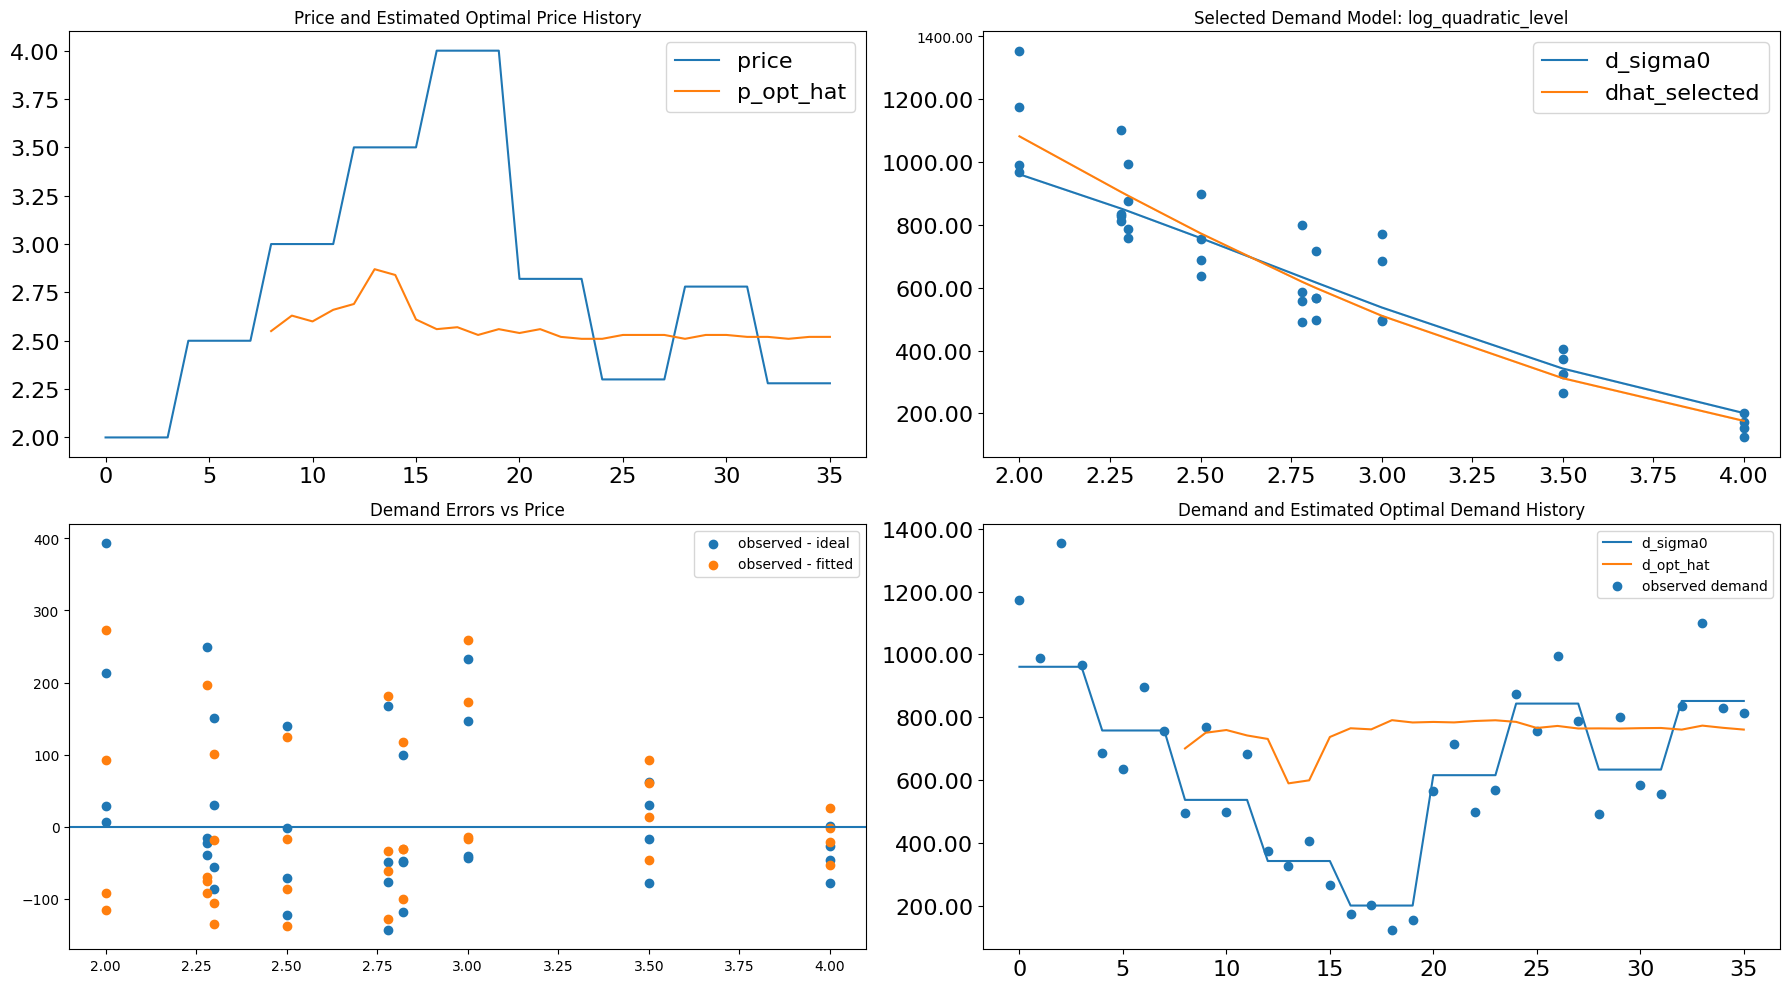

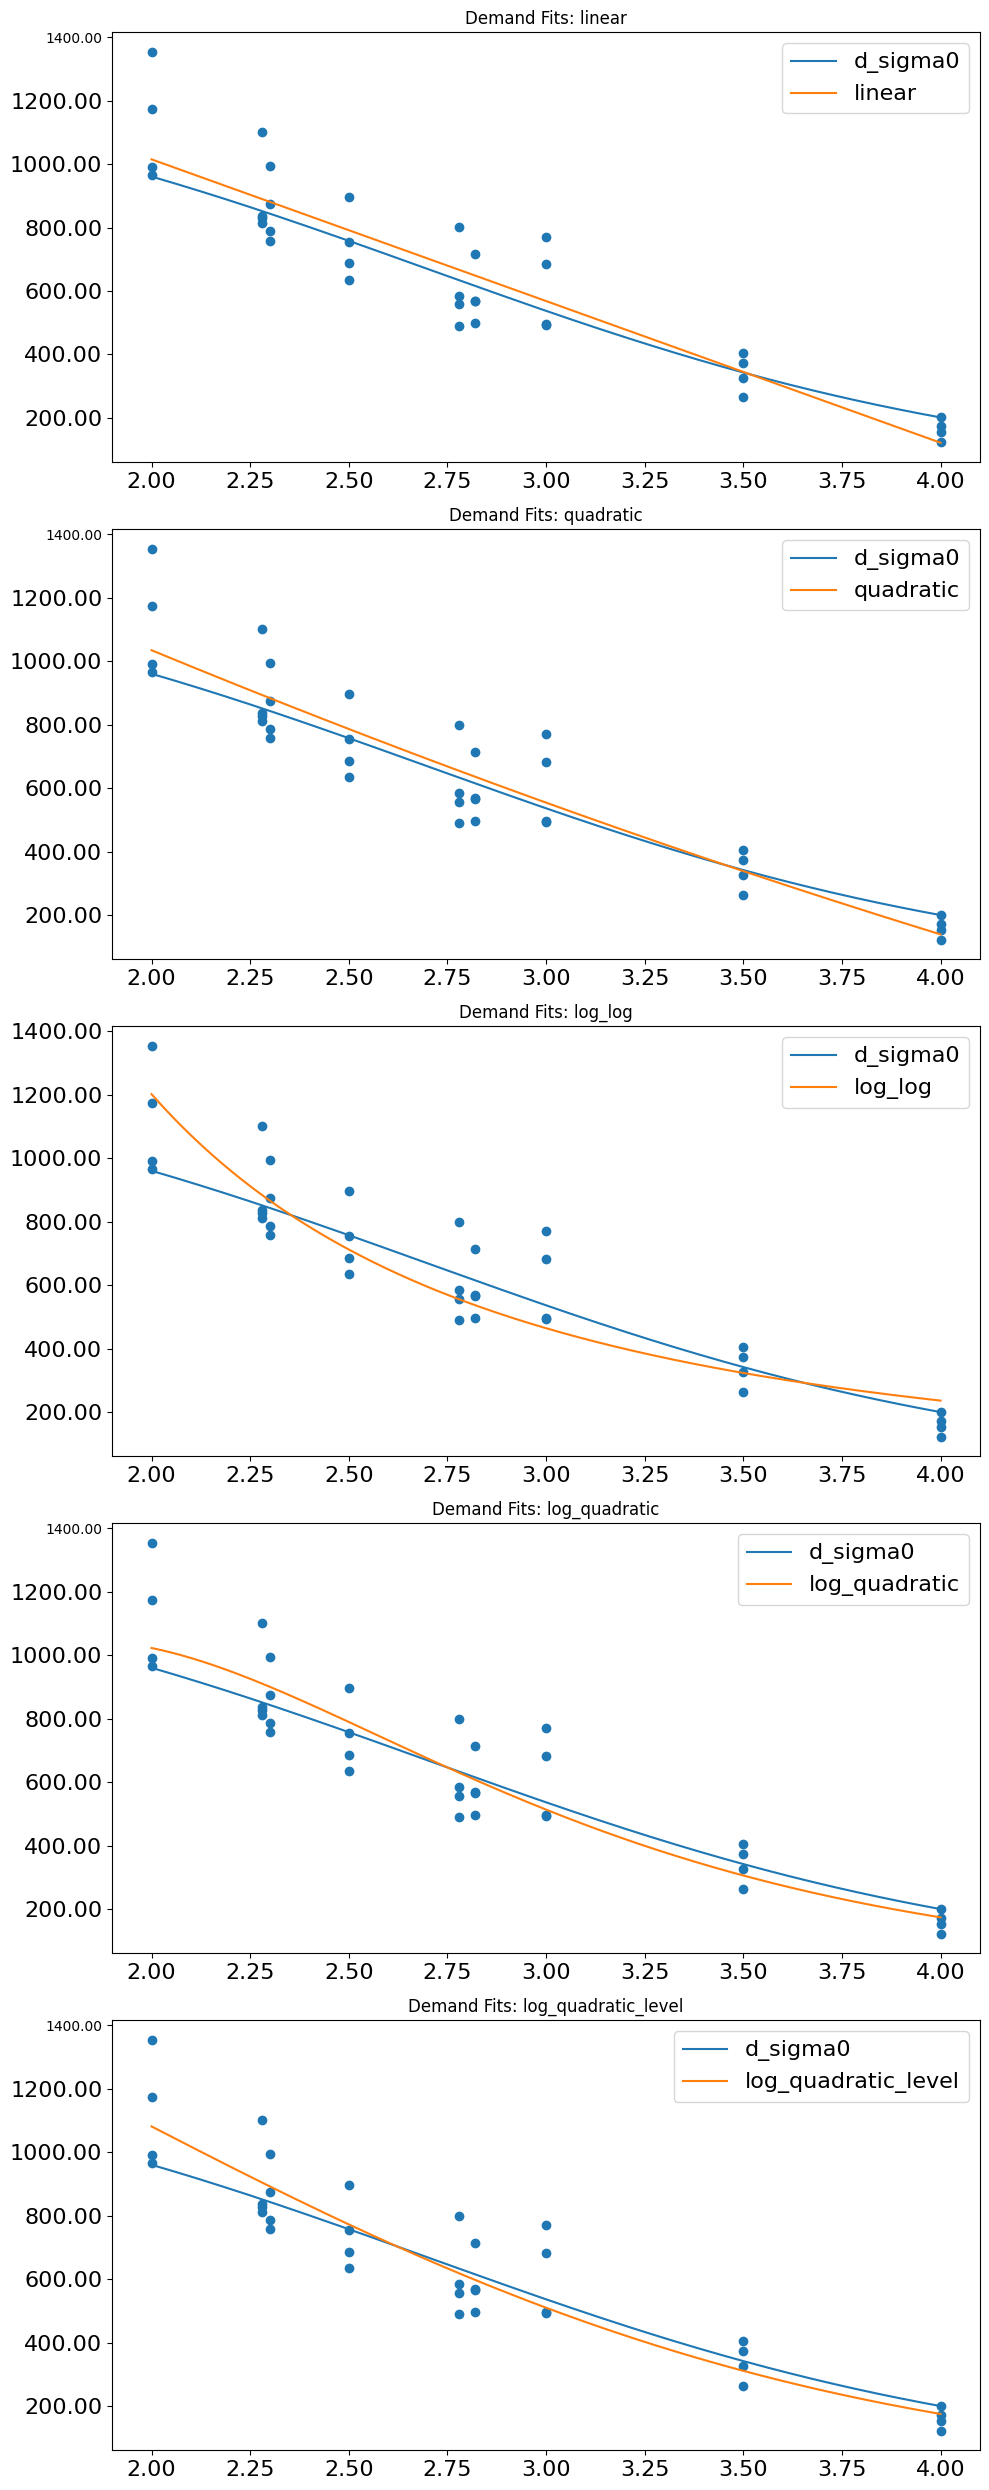


Final model diagnostics:

linear:
  AIC = -115.045
  RSS = 1.318785
  p_opt_hat = 2.737
  d_opt_hat = 685.4
  profit_opt_hat =1047.85
  tilt_error = 0.006246
  tilt_error_low = 27.825682
  tilt_error_high = 27.831928
  tilt_imbalance =  0.006246

quadratic:
  AIC = -121.591
  RSS = 1.040102
  p_opt_hat = 2.689
  d_opt_hat = 697.2
  profit_opt_hat =1032.33
  tilt_error = 8.725030
  tilt_error_low = 18.797680
  tilt_error_high = 27.522710

log_log:
  AIC = -104.358
  RSS = 1.774600
  p_opt_hat = 2.096
  d_opt_hat = 1076.9
  profit_opt_hat =959.07
  tilt_error = 0.002040
  tilt_error_low = -0.032214
  tilt_error_high = -0.030174

log_quadratic:
  AIC = -120.460
  RSS = 1.073292
  p_opt_hat = 2.533
  d_opt_hat = 771.2
  profit_opt_hat =1022.01
  tilt_error = 0.057317
  tilt_error_low = -0.001238
  tilt_error_high = 0.056079

log_quadratic_level:
  AIC = -122.162
  RSS = 1.023735
  p_opt_hat = 2.521
  d_opt_hat = 760.9
  profit_opt_hat =999.12
  tilt_error = 0.064878
  tilt_error_low = -0.

In [67]:
# ========== Evaluate Demand and Price Fits ============#

# -------------- extract experiment results -------------

k = len(results_dict_list) - 1
k = 46

print(f"Experiment k = {k}")
print(f"N_loop = {N_loop}")

results_dict_k = results_dict_list[k]

selected_model_type = results_dict_k["selected_model_type"]
model_diagnostics = results_dict_k["model_diagnostics"]
fitted_models = results_dict_k["fitted_models"]

# ------------- Experiment parameters ----------------

print(f"candidate_model_types = {candidate_model_types}")
print(f"tilt_penalty_linear = {tilt_penalty_linear}")
print(f"tilt_penalty_log_log = {tilt_penalty_log_log}")
print(f"tilt_penalty_log_quadratic = {tilt_penalty_log_quadratic}")
print(f"linear_tilt_imbalance_max = {linear_tilt_imbalance_max}")
print(f"logq_aic_improvement_min = {logq_aic_improvement_min}")
print(f"p_opt_linear_delta_frac_max = {p_opt_linear_delta_frac_max}")

print(f"demand_type = {demand_type}")
print(f"demand_params = {demand_params}")
print(f"sigma_log = {sigma_log}")
print(f"selected_model_type = {selected_model_type}")


# -------------- MAB histories ---------------------

p_history = np.asarray(results_dict_k["p_history"], dtype=float,)
d_history = np.asarray(results_dict_k["d_history"],dtype=float,)
d_sigma0_history = np.asarray( results_dict_k["d_sigma0_history"], dtype=float,)
p_opt_hat_history = np.asarray(  results_dict_k["p_opt_hat_history"], dtype=float,)
d_opt_hat_history = np.asarray(results_dict_k["d_opt_hat_history"], dtype=float,)

print(f"price_history = {p_history.tolist()}")
print(f"demand_history = {d_history.tolist()}")
print(f"d_sigma0_history = {d_sigma0_history.tolist()}")
print(f"d_opt_hat_history = {d_opt_hat_history.tolist()}")

# -------------- Fitted demand models -----------------

dhat_models = {
    model_type: fitted_models[model_type]["dhat_model"]
    for model_type in candidate_model_types
}

dhat_selected = dhat_models[selected_model_type]


# -------------- Sort observed data by price ------------

sort_idx = np.argsort(p_history)
p_sorted = p_history[sort_idx]
d_sorted = d_history[sort_idx]


# ---------- Demand predictions at observed prices ---------

dhat_selected_sorted = np.asarray(
    dhat_selected(p_sorted),
    dtype=float,
)

# noiseless demand at observed prices
d_sigma0_sorted = np.asarray(  
    get_demand(  demand_type,    demand_params,  p_sorted,sigma_log=0, ), dtype=float,)


# ---------------- Errors -----------------------

# observed demand - ideal noiseless demand
errors_out_of_sample = ( d_sorted - d_sigma0_sorted)

# observed demand - selected fitted demand
errors_residual = ( d_sorted - dhat_selected_sorted)

print(f"errors out-of-sample (observed demand - ideal demand) = {errors_out_of_sample.tolist()}")
print(  f"errors residual  (observed demand - selected fitted demand) = {errors_residual.tolist()}")


# ------------ Price grid --------------------------

p_grid = np.linspace(
    price_min,
    price_max,
    500,
)

d_sigma0_grid = np.asarray(
    get_demand(
        demand_type,
        demand_params,
        p_grid,
        sigma_log=0,
    ),
    dtype=float,
)


# ---------- Candidate-model predictions on price grid ----------

dhat_grid = {}

for model_type in candidate_model_types:

    dhat_grid[model_type] = np.asarray(
        dhat_models[model_type](p_grid),
        dtype=float,
    )


# ---------------- Selected-model optimum --------------------

selected_diagnostics = model_diagnostics[
    selected_model_type
]

print()
print(f"selected_model_type = {selected_model_type}")
print(f"p_opt_hat = {selected_diagnostics['p_opt_hat']:.3f}")
print(f"d_opt_hat = {selected_diagnostics['d_opt_hat']:.1f}")
print(f"profit_opt_hat = {selected_diagnostics['profit_opt_hat']:.2f}")


# ----------- Dataframes for plotting --------------

df_observed = pd.DataFrame({
    "price": p_sorted,
    "observed": d_sorted,
    "d_sigma0": d_sigma0_sorted,
    "dhat_selected": dhat_selected_sorted,
    "error_out_of_sample": errors_out_of_sample,
    "error_residual": errors_residual,
})


df_grid = pd.DataFrame({
    "price": p_grid,
    "d_sigma0": d_sigma0_grid,
})

# add each candidate-model prediction
for model_type in candidate_model_types:

    df_grid[model_type] = dhat_grid[ model_type]


df_history = pd.DataFrame({
    "i": np.arange(len(p_history)),
    "price": p_history,
    "p_opt_hat": p_opt_hat_history,
    "demand": d_history,
    "d_sigma0": d_sigma0_history,
    "d_opt_hat": d_opt_hat_history,
})


# ==========================================================
# Plot 1: MAB and selected-model diagnostics
# ==========================================================

_fig, axs = plt.subplots( nrows=2,   ncols=2,  figsize=(18, 10),)


# ---------- Price history ----------

bp.lineplot(  df_history, x="i",  y=["price", "p_opt_hat",],ax=axs[0][0],)

axs[0][0].set_title( "Price and Estimated Optimal Price History")


# ---------- Selected fitted curve vs observed demand ----------

bp.lineplot(
    df_observed,
    x="price",  y=[ "d_sigma0",  "dhat_selected", ],   linestyle="-",  ax=axs[0][1],)

axs[0][1].scatter( p_history,d_history,  marker="o",)

axs[0][1].set_title(
    f"Selected Demand Model: {selected_model_type}"
)


# ---------- Errors vs price ----------

axs[1][0].scatter(
    p_sorted,
    errors_out_of_sample,
    marker="o",
    label="observed - ideal",
)

axs[1][0].scatter(
    p_sorted,
    errors_residual,
    marker="o",
    label="observed - fitted",
)

axs[1][0].axhline(
    y=0,
    linestyle="-",
)

axs[1][0].legend()

axs[1][0].set_title(
    "Demand Errors vs Price"
)


# ---------- Demand history ----------

bp.lineplot( df_history,  x="i", y=["d_sigma0", "d_opt_hat",], ax=axs[1][1],)

axs[1][1].scatter(
    df_history["i"],   df_history["demand"],marker="o", label="observed demand",)

axs[1][1].legend()
axs[1][1].set_title("Demand and Estimated Optimal Demand History")

plt.tight_layout()
plt.show()


# ==========================================================
# Plot 2: Demand fit for each candidate model
# ==========================================================

N_models = len(candidate_model_types)

_fig, axs = plt.subplots(
    nrows=N_models,
    ncols=1,
    figsize=(10, 5 * N_models),
    squeeze=False,
)

axs = axs[:, 0]


for j, model_type in enumerate(
    candidate_model_types
):
    ax = axs[j]
    bp.lineplot(  df_grid,
        x="price",   y=[ "d_sigma0",model_type, ],
        linestyle="-", ax=ax )

    ax.scatter(p_history, d_history,  marker="o",)
    ax.set_title(  f"Demand Fits: {model_type}"
    )

plt.tight_layout()
plt.show()


# ==========================================================
# Final model diagnostics
# ==========================================================

print()
print("Final model diagnostics:")

for model_type in candidate_model_types:
    diagnostics = model_diagnostics[ model_type  ]

    print()
    print(f"{model_type}:")
    print(f"  AIC = {diagnostics['aic']:.3f}")
    print(f"  RSS = {diagnostics['rss']:.6f}")
    print(f"  p_opt_hat = {diagnostics['p_opt_hat']:.3f}")
    print(f"  d_opt_hat = {diagnostics['d_opt_hat']:.1f}" )
    print(f"  profit_opt_hat ={diagnostics['profit_opt_hat']:.2f}" )
    print(f"  tilt_error = {diagnostics['tilt_error']:.6f}")
    print(f"  tilt_error_low = {diagnostics['tilt_error_low']:.6f}")
    print(f"  tilt_error_high = {diagnostics['tilt_error_high']:.6f}")

    if model_type == "linear":
        print(f"  tilt_imbalance =  {diagnostics['tilt_imbalance']:.6f}")

# Statistical Performance Results

In [13]:
print(f"N_experiments = {N_experiments}")
print(f"Nloop = {N_loop}")
print(f"Nprice_repeat = {N_price_repeat}")
print(f"N_initial_prices = {N_initial_prices}")
print()
print(f"demand_type = {demand_type}")
print(f"candidate_model_types = {candidate_model_types}")
print(f"ridge_cv = {ridge_cv}")
print(f"huber = {huber}")
print(f"demand_params = {demand_params}")
print(f"boundary_buffer = {boundary_buffer}")
print()
print(f'CV = {CV}')
print(f"sigma_lg = {sigma_lg}")
print()
print(f"tilt_penalty_linear = {tilt_penalty_linear}")
print(f"tilt_penalty_log_log = {tilt_penalty_log_log}")
print(f"tilt_penalty_log_quadratic = {tilt_penalty_log_quadratic}")
print()
print(f"logq_aic_improvement_min = {logq_aic_improvement_min}")
print(f"p_opt_linear_delta_frac_max = {p_opt_linear_delta_frac_max}")


display(  df_experiments[cols].head(10).sort_values( "p_opt_hat",   ascending=False,  ))
print("...")
display(  df_experiments[cols].tail(10).sort_values( "p_opt_hat",   ascending=False,  ))

N_experiments = 100
Nloop = 36
Nprice_repeat = 4
N_initial_prices = 5

demand_type = logit
candidate_model_types = ['linear', 'quadratic', 'log_quadratic_level']
ridge_cv = True
huber = False
demand_params = {'A': 1338.5518896756485, 'a': 3.6, 'b': 1.3333333333333335}
boundary_buffer = 0.2

CV = 0.2
sigma_lg = 0.19804220043536505

tilt_penalty_linear = 20.0
tilt_penalty_log_log = 10.0
tilt_penalty_log_quadratic = 0.0

logq_aic_improvement_min = 2.0
p_opt_linear_delta_frac_max = 0.15


NameError: name 'df_experiments' is not defined

### Constant Elasticity

N_experiments = 100
N_price_repeat = 4
p_opt_hat max = 2.96
p_opt_hat_max = 
